# Importações e estrutura de pastas

In [34]:
# Biblioteca usada no balanceamento (SMOTE)
!pip install imbalanced-learn -q

import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report

from imblearn.over_sampling import SMOTE

# A base fica em data/ e os gráficos são salvos em outputs/
CAMINHO_DADOS = "data/dataset_recuperacao_telecom.csv"
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")

print("Ambiente pronto.")

Ambiente pronto.


# Fase 1: Análise Exploratória dos Dados (EDA)

Dimensões do dataset: 7068 linhas x 21 colunas

Tipos de dados:
id_cliente               object
genero                   object
idoso                     int64
tem_parceiro             object
tem_dependentes          object
meses_contrato          float64
servico_telefone         object
linhas_multiplas         object
servico_internet         object
seguranca_online         object
backup_online            object
protecao_dispositivo     object
suporte_tecnico          object
streaming_tv             object
streaming_filmes         object
tipo_contrato            object
fatura_digital           object
metodo_pagamento         object
valor_mensal            float64
valor_total             float64
cancelou                  int64
dtype: object

Valores ausentes por coluna:
meses_contrato    284
valor_mensal      354
valor_total        11
dtype: int64

Linhas duplicadas (linha inteira): 25
Duplicatas em id_cliente: 25

Proporção da variável alvo:
cancelou
0    0.7351
1    0.2649
Name: propo

,idoso,meses_contrato,valor_mensal,valor_total,cancelou
count,7068.00,6784.00,6714.00,7057.00,7068.00
mean,0.16,32.36,65.87,2283.28,0.26
std,0.37,24.56,40.99,2265.86,0.44
min,0.00,0.00,18.25,18.80,0.00
25%,0.00,9.00,35.65,401.95,0.00
50%,0.00,29.00,70.35,1398.60,0.00
75%,0.00,55.00,89.95,3791.60,1.00
max,1.00,72.00,921.40,8684.80,1.00


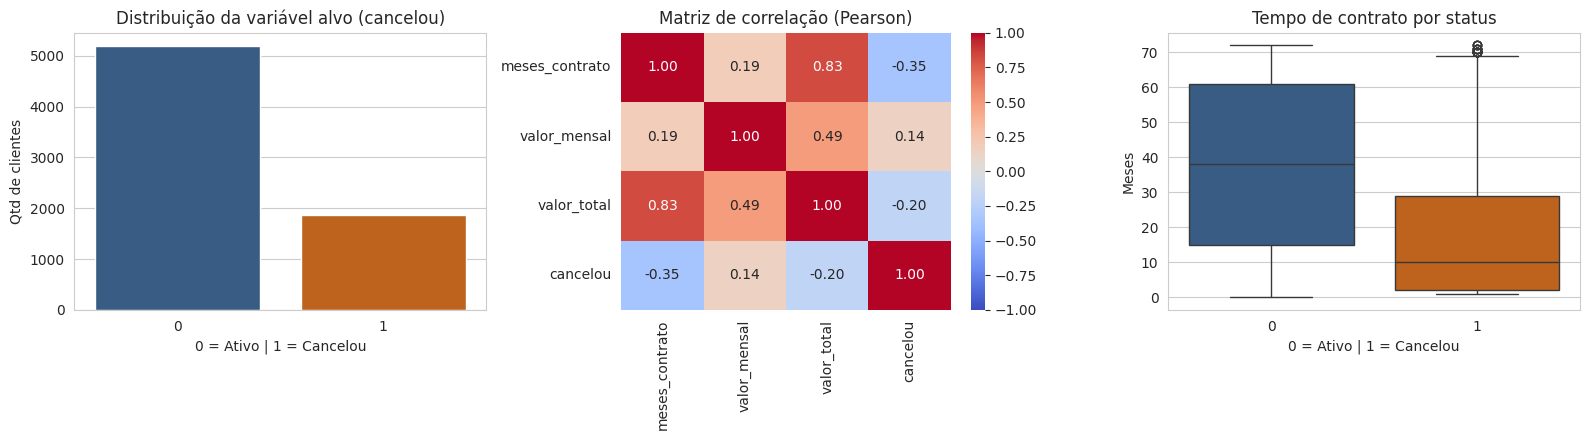

In [35]:
df_bruto = pd.read_csv(CAMINHO_DADOS)

linhas, colunas = df_bruto.shape
print(f"Dimensões do dataset: {linhas} linhas x {colunas} colunas\n")

print("Tipos de dados:")
print(df_bruto.dtypes)

print("\nValores ausentes por coluna:")
nulos = df_bruto.isna().sum()
print(nulos[nulos > 0])

print(f"\nLinhas duplicadas (linha inteira): {df_bruto.duplicated().sum()}")
print(f"Duplicatas em id_cliente: {df_bruto.duplicated(subset=['id_cliente']).sum()}")

print("\nProporção da variável alvo:")
print(df_bruto["cancelou"].value_counts(normalize=True).round(4))

print("\nMediana de meses de contrato por status:")
print(df_bruto.groupby("cancelou")["meses_contrato"].median())

print("\nEstatística descritiva das variáveis numéricas:")
display(df_bruto.describe().round(2))

# Gráficos
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Distribuição da variável alvo
sns.countplot(data=df_bruto, x="cancelou", hue="cancelou", ax=ax1, palette=["#2b5c8f", "#d95f02"], legend=False)
ax1.set_title("Distribuição da variável alvo (cancelou)")
ax1.set_xlabel("0 = Ativo | 1 = Cancelou")
ax1.set_ylabel("Qtd de clientes")

# 2. Correlação de Pearson
cols_corr = ["meses_contrato", "valor_mensal", "valor_total", "cancelou"]
sns.heatmap(df_bruto[cols_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax2)
ax2.set_title("Matriz de correlação (Pearson)")

# 3. Tempo de contrato por status
sns.boxplot(data=df_bruto, x="cancelou", y="meses_contrato", hue="cancelou", ax=ax3, palette=["#2b5c8f", "#d95f02"], legend=False)
ax3.set_title("Tempo de contrato por status")
ax3.set_xlabel("0 = Ativo | 1 = Cancelou")
ax3.set_ylabel("Meses")

plt.tight_layout()
plt.savefig("outputs/fase1_eda_analise_inicial.png", dpi=300, bbox_inches="tight")
plt.show()

### O que a EDA mostra

A base original tem 7.068 linhas e 21 colunas. Dessas, 25 são cópias exatas de outras linhas, então depois da limpeza ficam 7.043 clientes. Três colunas numéricas têm valores ausentes: `valor_mensal` (cerca de 5%), `meses_contrato` (4%) e `valor_total` (menos de 1%).

A variável alvo é desbalanceada: perto de 73,5% dos clientes seguem ativos e 26,5% cancelaram. Um modelo que respondesse "ativo" para todo mundo já acertaria 73,5%, então a acurácia sozinha engana. Por isso a divisão vai usar `stratify=y`, o SMOTE só entra no treino e eu vou olhar também o recall.

No mapa de calor, `meses_contrato` e `valor_total` andam juntas (r = 0,83), o que faz sentido porque o total acumulado cresce com o tempo de casa. O cancelamento tem correlação negativa com `meses_contrato` (-0,35): a mediana de quem cancelou é de 10 meses, contra 38 de quem ficou. Ou seja, o churn se concentra no começo do contrato. Já `valor_mensal` tem correlação fraca com o cancelamento (0,14). A coluna `id_cliente` não entra no modelo, só identifica o cadastro.

# Fase 2: Limpeza e tratamento dos dados

Linhas removidas por duplicidade: 25
Linhas restantes: 7043

Assimetria (skew) antes do tratamento:
meses_contrato    0.24
valor_mensal      7.88
valor_total       0.96
dtype: float64

Valores de valor_mensal acima de R$ 300: 11

Imputação:
meses_contrato: 282 nulos preenchidos com a mediana (29.00)
valor_mensal: 363 nulos preenchidos com a mediana (70.35)
valor_total: 11 nulos preenchidos com a mediana (1397.47)

Assimetria (skew) depois do tratamento:
meses_contrato    0.26
valor_mensal     -0.24
valor_total       0.96
dtype: float64

Nulos restantes no dataset: 0


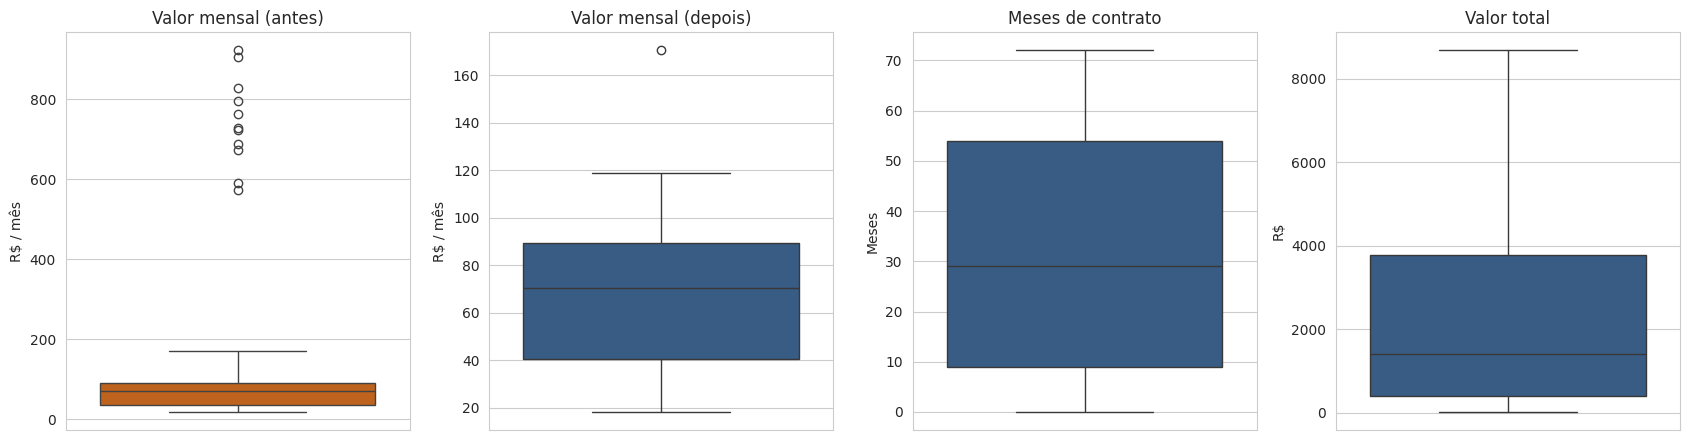

In [36]:
df_tratado = df_bruto.copy()
cols_num = ["meses_contrato", "valor_mensal", "valor_total"]

# 1. Duplicatas
linhas_antes = len(df_tratado)
df_tratado = df_tratado.drop_duplicates(subset=["id_cliente"], keep="first").reset_index(drop=True)
print(f"Linhas removidas por duplicidade: {linhas_antes - len(df_tratado)}")
print(f"Linhas restantes: {len(df_tratado)}")

# 2. Assimetria antes de mexer nos outliers
print("\nAssimetria (skew) antes do tratamento:")
print(df_tratado[cols_num].skew().round(2))

# guarda o valor_mensal original para comparar nos boxplots
valor_mensal_antes = df_tratado["valor_mensal"].copy()

# 3. Outliers de valor_mensal (acima de R$ 300)
outliers_mensal = df_tratado["valor_mensal"] > 300
print(f"\nValores de valor_mensal acima de R$ 300: {outliers_mensal.sum()}")
df_tratado.loc[outliers_mensal, "valor_mensal"] = np.nan

# 4. Imputação pela mediana
print("\nImputação:")
for col in cols_num:
    qtd_nulos = df_tratado[col].isna().sum()
    mediana = df_tratado[col].median()
    df_tratado[col] = df_tratado[col].fillna(mediana)
    print(f"{col}: {qtd_nulos} nulos preenchidos com a mediana ({mediana:.2f})")

print("\nAssimetria (skew) depois do tratamento:")
print(df_tratado[cols_num].skew().round(2))
print(f"\nNulos restantes no dataset: {df_tratado.isna().sum().sum()}")

# 5. Boxplots das variáveis explicativas
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))

sns.boxplot(y=valor_mensal_antes, ax=axes[0], color="#d95f02")
axes[0].set_title("Valor mensal (antes)")
axes[0].set_ylabel("R$ / mês")

sns.boxplot(y=df_tratado["valor_mensal"], ax=axes[1], color="#2b5c8f")
axes[1].set_title("Valor mensal (depois)")
axes[1].set_ylabel("R$ / mês")

sns.boxplot(y=df_tratado["meses_contrato"], ax=axes[2], color="#2b5c8f")
axes[2].set_title("Meses de contrato")
axes[2].set_ylabel("Meses")

sns.boxplot(y=df_tratado["valor_total"], ax=axes[3], color="#2b5c8f")
axes[3].set_title("Valor total")
axes[3].set_ylabel("R$")

plt.tight_layout()
plt.savefig("outputs/fase2_boxplots_outliers.png", dpi=300, bbox_inches="tight")
plt.show()

### Limpeza

**Duplicatas.** As 25 linhas repetidas eram cópias exatas, então usei `drop_duplicates` pelo `id_cliente`, mantendo a primeira ocorrência.

**Outliers.** No primeiro boxplot de `valor_mensal` aparecem 11 pontos entre R$ 573 e R$ 921, muito longe do resto da coluna, que vai no máximo até R$ 170 e tem mediana de R$ 70. Quando olhei o gasto histórico desses mesmos clientes (`valor_total` dividido por `meses_contrato`), ele fica entre R$ 62 e R$ 106, normal para a base. Por isso tratei como erro de digitação ou de escala, e não como plano caro de verdade. Troquei esses valores por NaN para imputar junto com os ausentes. O corte de R$ 300 fica no meio do vazio que existe entre R$ 170 e R$ 573. Depois do tratamento, `meses_contrato` e `valor_total` não têm pontos fora dos limites do boxplot, e `valor_mensal` ficou com um único, perto de R$ 170, que mantive por estar numa faixa plausível.

**Imputação.** Antes do tratamento, a assimetria era 0,24 em `meses_contrato`, 0,96 em `valor_total` e 7,88 em `valor_mensal`, esta última puxada pelos 11 outliers. Depois de tirá-los, `valor_mensal` caiu para -0,24 e `valor_total` continuou com cauda à direita. Como `valor_total` é assimétrica e a média seria puxada pelos clientes mais antigos, usei a mediana nas três colunas, para manter um critério único. A saída mostra zero nulos no final.

Uma observação: fiz a imputação antes de separar treino e teste porque o edital trata a limpeza como uma fase própria. Como a mediana de 7 mil linhas muda pouco, o efeito é pequeno, mas o mais correto seria calcular a mediana só com o treino. Deixo isso como melhoria.

# Fase 3: Feature Engineering

In [37]:
# gasto médio por mês de contrato = valor_total / meses_contrato
# se meses_contrato for 0 (sem nenhum mês completo), usa o próprio valor_mensal
meses_validos = df_tratado["meses_contrato"].replace(0, np.nan)

df_tratado["gasto_medio_mensal"] = (
    (df_tratado["valor_total"] / meses_validos)
    .fillna(df_tratado["valor_mensal"])
    .round(2)
)

print(f"Clientes com meses_contrato = 0: {(df_tratado['meses_contrato'] == 0).sum()}")
print(f"Nulos em gasto_medio_mensal: {df_tratado['gasto_medio_mensal'].isna().sum()}")
print(f"Infinitos em gasto_medio_mensal: {np.isinf(df_tratado['gasto_medio_mensal']).sum()}")

display(df_tratado[["meses_contrato", "valor_total", "valor_mensal", "gasto_medio_mensal"]].head(10))

Clientes com meses_contrato = 0: 11
Nulos em gasto_medio_mensal: 0
Infinitos em gasto_medio_mensal: 0


,meses_contrato,valor_total,valor_mensal,gasto_medio_mensal
0,1.0,29.85,29.85,29.85
1,34.0,1889.50,56.95,55.57
2,2.0,108.15,53.85,54.08
3,45.0,1840.75,42.30,40.91
4,2.0,151.65,70.70,75.82
5,8.0,820.50,99.65,102.56
6,22.0,1949.40,89.10,88.61
7,10.0,301.90,29.75,30.19
8,28.0,3046.05,104.80,108.79
9,29.0,3487.95,56.15,120.27


### Nova variável: `gasto_medio_mensal`

Criei `gasto_medio_mensal = valor_total / meses_contrato`, como o departamento sugeriu. A ideia é comparar o que o cliente paga hoje (`valor_mensal`) com o que ele pagou em média ao longo do contrato. Se a fatura atual está bem acima da média histórica, pode ter havido reajuste ou troca de plano, e isso pode pesar na decisão de cancelar.

Sobre a conta: 11 clientes têm `meses_contrato = 0` e, como o `valor_total` deles estava ausente, ele foi preenchido com a mediana (R$ 1.397). Dividir isso por zero daria infinito, e se eu somasse 1 no denominador o gasto médio desses clientes ficaria em R$ 1.397 por mês, o que não faz sentido. Para esses casos usei o próprio `valor_mensal`. A coluna ficou sem nulos e sem infinitos.

Uma limitação: em cerca de 4% dos clientes o `meses_contrato` foi imputado com a mediana (29 meses), então o gasto médio deles é só uma estimativa.

# Fase 4: Divisão e balanceamento dos dados

In [38]:
# Separação entre preditoras (X) e alvo (y), sem o id_cliente
X = df_tratado.drop(columns=["id_cliente", "cancelou"])
y = df_tratado["cancelou"].astype(int)

# Colunas de texto viram 0/1
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# Divisão 80/20 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print("=== ANTES DO SMOTE ===")
print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")
print(f"Proporção de churn no treino: {y_train.mean():.2%}")
print(f"Proporção de churn no teste:  {y_test.mean():.2%}")

# SMOTE só no treino
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("\n=== DEPOIS DO SMOTE (só treino) ===")
print(f"Treino reamostrado: {X_train_res.shape}")
print(y_train_res.value_counts())
print(f"\nTeste intacto: {X_test.shape}")

=== ANTES DO SMOTE ===
Treino: (5634, 31) | Teste: (1409, 31)
Proporção de churn no treino: 26.54%
Proporção de churn no teste:  26.54%

=== DEPOIS DO SMOTE (só treino) ===
Treino reamostrado: (8278, 31)
cancelou
0    4139
1    4139
Name: count, dtype: int64

Teste intacto: (1409, 31)


### Divisão e balanceamento

Tirei `id_cliente` (só identifica o cadastro) e `cancelou` de X, e transformei as colunas de texto em 0/1 com `get_dummies(drop_first=True)`, o que deixou 31 colunas. A divisão ficou 80/20 com `stratify=y`, então treino e teste mantêm os mesmos 26,54% de cancelamentos.

O SMOTE entrou só depois da divisão e só no treino: ele cria clientes sintéticos da classe que cancelou até igualar as duas classes (4.139 de cada). Se eu tivesse balanceado antes de dividir, exemplos sintéticos gerados a partir de clientes do teste poderiam cair no treino (data leakage) e a acurácia ficaria otimista. O teste continua com a proporção real de clientes.

# Fase 5: Escalonamento das variáveis

In [39]:
cols_continuas = ["meses_contrato", "valor_mensal", "valor_total", "gasto_medio_mensal"]

# cópias, para a árvore continuar com os dados sem escala
X_train_knn = X_train_res.copy()
X_test_knn = X_test.copy()

# fit só no treino, o teste só recebe transform
scaler = StandardScaler()
X_train_knn[cols_continuas] = scaler.fit_transform(X_train_res[cols_continuas])
X_test_knn[cols_continuas] = scaler.transform(X_test[cols_continuas])

print("Colunas padronizadas (KNN):", cols_continuas)
print("A Árvore de Decisão usa X_train_res e X_test, sem padronização.")

Colunas padronizadas (KNN): ['meses_contrato', 'valor_mensal', 'valor_total', 'gasto_medio_mensal']
A Árvore de Decisão usa X_train_res e X_test, sem padronização.


### Escalonamento

Padronizei com `StandardScaler` só as quatro colunas contínuas (`meses_contrato`, `valor_mensal`, `valor_total` e `gasto_medio_mensal`) e só para o KNN. As colunas 0/1 ficaram como estão. O `fit_transform` foi feito no treino e o teste recebeu apenas `transform`, para que a média e o desvio do teste não influenciem o ajuste.

O KNN trabalha com distâncias, e sem padronização o `valor_total` (que vai a milhares) dominaria o `meses_contrato` (no máximo 72). A Árvore de Decisão não precisa disso: cada divisão compara uma coluna com um limite, e mudar a escala não muda quais clientes ficam de cada lado. Por isso ela usa os dados originais.

# Fase 6: Ajuste de parâmetros e overfitting

=== KNN ===


,K,Acc Treino (SMOTE),Acc Teste,Gap (treino - teste),Recall Teste
0,3,0.8920,0.7431,0.1489,0.6551
1,5,0.8719,0.7268,0.1452,0.6631
2,7,0.8547,0.7445,0.1102,0.7246
3,9,0.8497,0.7388,0.1109,0.7219
4,11,0.8425,0.7289,0.1136,0.7299
5,13,0.8369,0.7346,0.1024,0.7487
6,15,0.8326,0.7211,0.1115,0.7540



=== ÁRVORE DE DECISÃO ===


,Profundidade,Acc Treino (SMOTE),Acc Teste,Gap (treino - teste),Recall Teste
0,3,0.7748,0.6870,0.0878,0.7380
1,5,0.8039,0.7466,0.0573,0.6791
2,7,0.8316,0.7331,0.0985,0.6925
3,10,0.8699,0.7459,0.1240,0.6631
4,Sem limite,0.9987,0.7211,0.2776,0.5374



Melhor K (maior acurácia no teste): 7
Melhor max_depth (maior acurácia no teste): 5


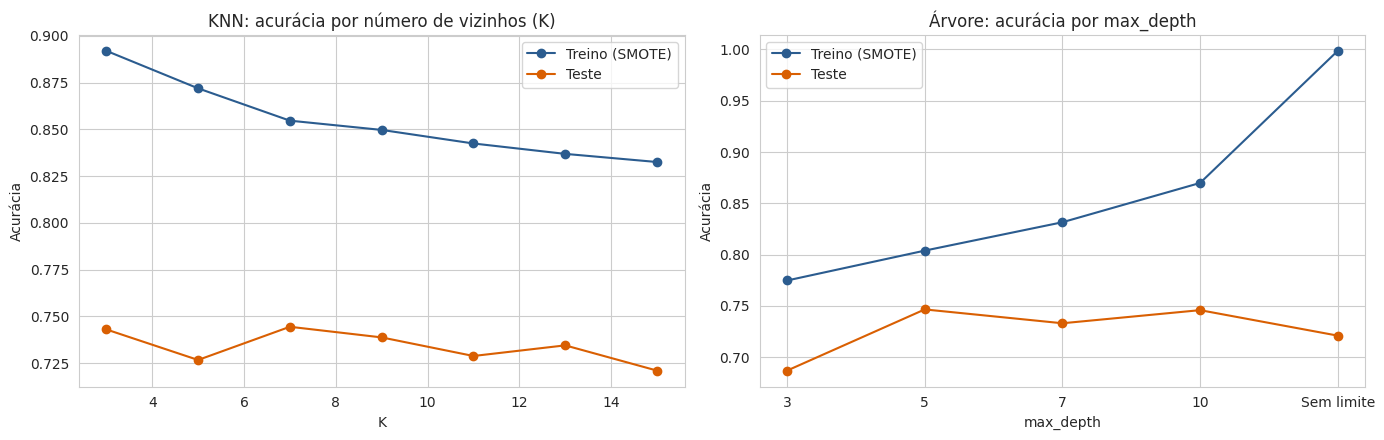

In [40]:
# KNN: variando K
k_valores = [3, 5, 7, 9, 11, 13, 15]
res_knn = []

for k in k_valores:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_res)

    pred_tr = knn.predict(X_train_knn)
    pred_te = knn.predict(X_test_knn)

    acc_tr = accuracy_score(y_train_res, pred_tr)
    acc_te = accuracy_score(y_test, pred_te)
    res_knn.append({
        "K": k,
        "Acc Treino (SMOTE)": acc_tr,
        "Acc Teste": acc_te,
        "Gap (treino - teste)": acc_tr - acc_te,
        "Recall Teste": recall_score(y_test, pred_te),
    })

df_knn = pd.DataFrame(res_knn)

# Árvore: variando max_depth
profundidades = [3, 5, 7, 10, None]
res_tree = []

for depth in profundidades:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train_res, y_train_res)

    pred_tr = tree.predict(X_train_res)
    pred_te = tree.predict(X_test)

    acc_tr = accuracy_score(y_train_res, pred_tr)
    acc_te = accuracy_score(y_test, pred_te)
    res_tree.append({
        "Profundidade": "Sem limite" if depth is None else str(depth),
        "Acc Treino (SMOTE)": acc_tr,
        "Acc Teste": acc_te,
        "Gap (treino - teste)": acc_tr - acc_te,
        "Recall Teste": recall_score(y_test, pred_te),
    })

df_tree = pd.DataFrame(res_tree)

print("=== KNN ===")
display(df_knn.round(4))
print("\n=== ÁRVORE DE DECISÃO ===")
display(df_tree.round(4))

# Melhor valor de cada modelo, pela acurácia no teste
melhor_k = k_valores[df_knn["Acc Teste"].idxmax()]
melhor_prof = profundidades[df_tree["Acc Teste"].idxmax()]
print(f"\nMelhor K (maior acurácia no teste): {melhor_k}")
print(f"Melhor max_depth (maior acurácia no teste): {melhor_prof}")

# Gráficos treino x teste
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(df_knn["K"], df_knn["Acc Treino (SMOTE)"], marker="o", label="Treino (SMOTE)", color="#2b5c8f")
ax1.plot(df_knn["K"], df_knn["Acc Teste"], marker="o", label="Teste", color="#d95f02")
ax1.set_title("KNN: acurácia por número de vizinhos (K)")
ax1.set_xlabel("K")
ax1.set_ylabel("Acurácia")
ax1.legend()

ax2.plot(df_tree["Profundidade"], df_tree["Acc Treino (SMOTE)"], marker="o", label="Treino (SMOTE)", color="#2b5c8f")
ax2.plot(df_tree["Profundidade"], df_tree["Acc Teste"], marker="o", label="Teste", color="#d95f02")
ax2.set_title("Árvore: acurácia por max_depth")
ax2.set_xlabel("max_depth")
ax2.set_ylabel("Acurácia")
ax2.legend()

plt.tight_layout()
plt.savefig("outputs/fase6_analise_overfitting.png", dpi=300, bbox_inches="tight")
plt.show()

### Overfitting nos dois modelos

Testei K de 3 a 15 (só ímpares) no KNN e `max_depth` igual a 3, 5, 7, 10 e sem limite na árvore, guardando a acurácia no treino, a acurácia no teste, a diferença entre as duas (coluna Gap) e o recall no teste. Uma ressalva: a acurácia de treino é medida no treino já balanceado pelo SMOTE, com clientes sintéticos, então serve mais para ver a distância até o teste do que como medida de desempenho.

**KNN.** Com K pequeno o modelo se agarra aos poucos vizinhos mais próximos e acaba memorizando ruído, e é onde a diferença entre treino e teste é maior: em K=3 ela passa de 14 pontos. Quando o K aumenta, essa diferença cai para cerca de 11 pontos, mas a acurácia no teste quase não muda, só oscila entre 72,1% e 74,5%. Também percebi que o recall sobe junto com o K, de 65,5% em K=3 para 75,4% em K=15: valores maiores detectam mais cancelamentos, só que errando mais clientes ativos. O K final é o de maior acurácia no teste, como pede o edital: K=7, com 74,45%.

**Árvore.** Sem limite de profundidade a árvore chega a 99,87% no treino contra 72,11% no teste, uma diferença de quase 28 pontos, que é o overfitting clássico: ela decorou os clientes de treino. No outro extremo, com profundidade 3 a acurácia de treino já é a mais baixa de todas (77,48%) e a de teste também (68,70%), sinal de que a árvore ficou simples demais (subajuste). A profundidade escolhida foi 5, com 74,66% no teste, entre esses dois extremos.

# Fase 7: Avaliação final e escolha do modelo

=== RESULTADOS NO CONJUNTO DE TESTE ===
Baseline (tudo 'ativo'): acurácia = 73.46% | recall = 0.00%
KNN (K=7): acurácia = 74.45% | recall = 72.46%
Árvore de Decisão (max_depth=5): acurácia = 74.66% | recall = 67.91%

Modelo com maior acurácia no teste: Árvore de Decisão (max_depth=5)
Diferença entre as acurácias: 0.21 pontos percentuais

Relatório - KNN (K=7)
              precision    recall  f1-score   support

   Ativo (0)       0.88      0.75      0.81      1035
Cancelou (1)       0.51      0.72      0.60       374

    accuracy                           0.74      1409
   macro avg       0.70      0.74      0.71      1409
weighted avg       0.78      0.74      0.76      1409

Relatório - Árvore de Decisão (max_depth=5)
              precision    recall  f1-score   support

   Ativo (0)       0.87      0.77      0.82      1035
Cancelou (1)       0.52      0.68      0.59       374

    accuracy                           0.75      1409
   macro avg       0.69      0.73      0.70      

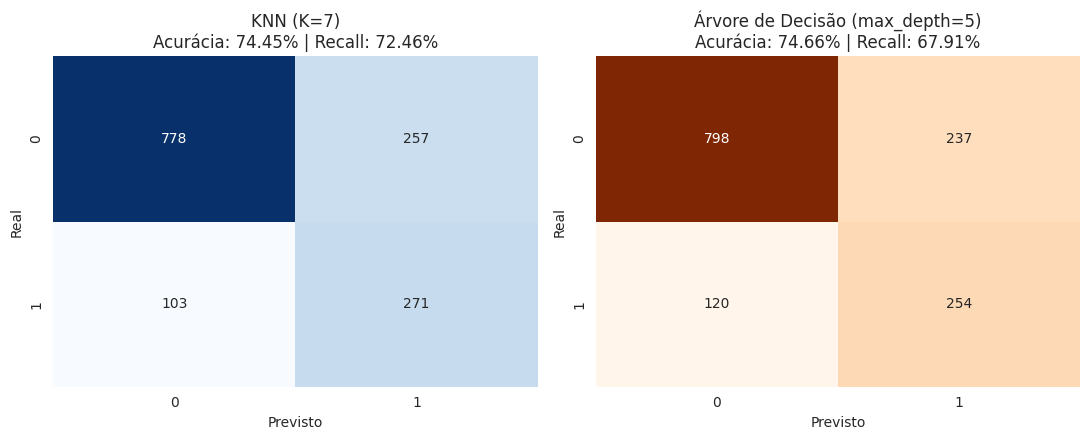

In [41]:
# Modelos finais com os melhores parâmetros da Fase 6
melhor_knn = KNeighborsClassifier(n_neighbors=melhor_k)
melhor_knn.fit(X_train_knn, y_train_res)
pred_knn = melhor_knn.predict(X_test_knn)

melhor_tree = DecisionTreeClassifier(max_depth=melhor_prof, random_state=42)
melhor_tree.fit(X_train_res, y_train_res)
pred_tree = melhor_tree.predict(X_test)

acc_knn = accuracy_score(y_test, pred_knn)
rec_knn = recall_score(y_test, pred_knn)
acc_tree = accuracy_score(y_test, pred_tree)
rec_tree = recall_score(y_test, pred_tree)

# Referência: prever "ativo" para todos os clientes
baseline = 1 - y_test.mean()

nome_knn = f"KNN (K={melhor_k})"
nome_tree = f"Árvore de Decisão (max_depth={melhor_prof})"

print("=== RESULTADOS NO CONJUNTO DE TESTE ===")
print(f"Baseline (tudo 'ativo'): acurácia = {baseline:.2%} | recall = 0.00%")
print(f"{nome_knn}: acurácia = {acc_knn:.2%} | recall = {rec_knn:.2%}")
print(f"{nome_tree}: acurácia = {acc_tree:.2%} | recall = {rec_tree:.2%}")

if acc_tree >= acc_knn:
    modelo_final = nome_tree
else:
    modelo_final = nome_knn

print(f"\nModelo com maior acurácia no teste: {modelo_final}")
print(f"Diferença entre as acurácias: {abs(acc_tree - acc_knn) * 100:.2f} pontos percentuais")

nomes = ["Ativo (0)", "Cancelou (1)"]
print(f"\nRelatório - {nome_knn}")
print(classification_report(y_test, pred_knn, target_names=nomes))
print(f"Relatório - {nome_tree}")
print(classification_report(y_test, pred_tree, target_names=nomes))

# Matrizes de confusão
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(confusion_matrix(y_test, pred_knn), annot=True, fmt="d", cmap="Blues", ax=ax1, cbar=False)
ax1.set_title(f"{nome_knn}\nAcurácia: {acc_knn:.2%} | Recall: {rec_knn:.2%}")
ax1.set_xlabel("Previsto")
ax1.set_ylabel("Real")

sns.heatmap(confusion_matrix(y_test, pred_tree), annot=True, fmt="d", cmap="Oranges", ax=ax2, cbar=False)
ax2.set_title(f"{nome_tree}\nAcurácia: {acc_tree:.2%} | Recall: {rec_tree:.2%}")
ax2.set_xlabel("Previsto")
ax2.set_ylabel("Real")

plt.tight_layout()
plt.savefig("outputs/fase7_matrizes_confusao_finais.png", dpi=300, bbox_inches="tight")
plt.show()

### Escolha do modelo

No teste, a Árvore de Decisão (`max_depth=5`) teve acurácia de 74,66% e o KNN (K=7) teve 74,45%. A diferença é de 0,21 ponto percentual, o que dá 3 clientes a mais acertados pela árvore entre os 1.409 do conjunto de teste. Os dois modelos ficaram só um pouco acima do baseline de 73,46%, que é a acurácia de quem responde "ativo" para todo mundo. Por isso a acurácia sozinha não diz muita coisa neste problema, e olhei também o recall.

Pelo critério do edital, a maior acurácia no teste, o modelo que eu recomendo é a **Árvore de Decisão (`max_depth=5`)**.

Só que uma diferença de 0,21 ponto é pequena demais para dizer que um modelo é de fato melhor que o outro, ela cabe dentro do que muda de uma execução para outra do SMOTE. Quando olho o recall, o KNN pega mais cancelamentos: encontrou 72,46% dos 374 clientes que cancelaram no teste, contra 67,91% da árvore. Na prática, a árvore deixou passar 120 cancelamentos e o KNN deixou passar 103, uma diferença de 17 clientes. A precisão é parecida (0,52 na árvore e 0,51 no KNN), então o KNN não acerta mais cancelamentos à custa de errar muito mais.

Se a prioridade da empresa fosse não deixar nenhum cancelamento passar, o KNN seria uma opção a considerar. Mesmo assim, mantenho a árvore como modelo adotado por dois motivos. Ela teve a maior acurácia, que é o critério do projeto, e as regras dela podem ser lidas pela equipe de marketing, que consegue entender por que um cliente foi apontado como risco. O KNN só diz que o cliente se parece com outros, e isso é mais difícil de usar para montar uma campanha de retenção.

Um último cuidado: escolhi o K e o `max_depth` olhando o próprio conjunto de teste, como o edital pede, então esses números finais são um pouco otimistas em relação ao que aconteceria com clientes novos.

### O que eu melhoraria

- Escolher os parâmetros com validação cruzada ou `GridSearchCV`, em vez de olhar o teste.
- Calcular a mediana da imputação só com o treino, por exemplo dentro de um `Pipeline`, para não usar informação do teste.
- Estimar o `meses_contrato` ausente a partir de `valor_total / valor_mensal`, em vez de usar a mediana de 29 meses para todo mundo.
- Testar outros modelos, como Random Forest e regressão logística, e ajustar o limiar de decisão para ganhar recall.